In [1]:

# !pip install xarray netCDF4 dask

import os
import re
import glob
import numpy as np
import xarray as xr
import pandas as pd


# Temperature

In [2]:
data_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc"  # 放 nc 文件的目录，例如 r"D:\HYCOM\2025_temp"
pattern  = "HYCOM_2025_water_temp_M*.nc"  # 文件名模式
out_nc   = "HYCOM_2025_water_temp_ALL.nc" # 输出文件名

# （可选）只拼接某一个变量，减少内存和输出体积；不知道变量名就先 None
only_var = None   # 例如 "water_temp"；不知道就保持 None


In [3]:
files = glob.glob(os.path.join(data_dir, pattern))

def month_key(fname):
    # 从文件名里抓 "M01".."M12"
    m = re.search(r"_M(\d{2})\.nc$", os.path.basename(fname))
    return int(m.group(1)) if m else 999

files = sorted(files, key=month_key)

print("找到文件数:", len(files))
for f in files:
    print(" -", os.path.basename(f))

找到文件数: 12
 - HYCOM_2025_water_temp_M01.nc
 - HYCOM_2025_water_temp_M02.nc
 - HYCOM_2025_water_temp_M03.nc
 - HYCOM_2025_water_temp_M04.nc
 - HYCOM_2025_water_temp_M05.nc
 - HYCOM_2025_water_temp_M06.nc
 - HYCOM_2025_water_temp_M07.nc
 - HYCOM_2025_water_temp_M08.nc
 - HYCOM_2025_water_temp_M09.nc
 - HYCOM_2025_water_temp_M10.nc
 - HYCOM_2025_water_temp_M11.nc
 - HYCOM_2025_water_temp_M12.nc


In [4]:
for file in files:
    ds_check = xr.open_dataset(file, decode_times=False)
    ds_check = ds_check['water_temp']
    x = ds_check.isel(depth=0)
    spstd = x.std(dim=('lat', 'lon'), skipna=True)
    bad = np.where(spstd.values < 1e-4)[0]
    print('bad time steps in', os.path.basename(file), ':', bad,'count=', len(bad))
    ds_check.close()




bad time steps in HYCOM_2025_water_temp_M01.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M02.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M03.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M04.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M05.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M06.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M07.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M08.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M09.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M10.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M11.nc : [] count= 0
bad time steps in HYCOM_2025_water_temp_M12.nc : [] count= 0


In [5]:
# 常见时间维度候选名（按优先级）
time_dim_candidates = ["time", "Time", "MT", "t", "datetime", "date"]

ds0 = xr.open_dataset(files[0])

print(ds0)
print("\n维度:", ds0.dims)
print("变量:", list(ds0.data_vars))

time_dim = None
for cand in time_dim_candidates:
    if cand in ds0.dims:
        time_dim = cand
        break

if time_dim is None:
    raise ValueError("没找到时间维度（time/MT/Time...）。请打开 ds0 看看实际维度名，然后手动指定。")

print("\n识别到时间维度:", time_dim)

<xarray.Dataset> Size: 609MB
Dimensions:     (time: 248, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth       (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2.5e+03 3e+03 4e+03
  * lat         (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.44 27.48 27.52
  * lon         (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time        (time) datetime64[ns] 2kB 2025-01-01T12:00:00 ... 2025-02-01T...
Data variables:
    water_temp  (time, depth, lat, lon) float32 609MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CIC

In [6]:
datasets = []

for f in files:
    print("读取:", os.path.basename(f))
    ds = xr.open_dataset(
        f,
        chunks={time_dim: 50}  # 适当调大/调小都行；或者删掉这一行做全内存
    )
    
    # （可选）只保留某个变量
    if only_var is not None:
        if only_var not in ds.data_vars:
            raise ValueError(f"{os.path.basename(f)} 里没有变量 {only_var}，请检查变量名。")
        ds = ds[[only_var]]
    
    datasets.append(ds)

# 拼接：沿 time_dim 维度连接
ds_all = xr.concat(datasets, dim=time_dim)

print(ds_all)

读取: HYCOM_2025_water_temp_M01.nc
读取: HYCOM_2025_water_temp_M02.nc
读取: HYCOM_2025_water_temp_M03.nc
读取: HYCOM_2025_water_temp_M04.nc
读取: HYCOM_2025_water_temp_M05.nc
读取: HYCOM_2025_water_temp_M06.nc
读取: HYCOM_2025_water_temp_M07.nc
读取: HYCOM_2025_water_temp_M08.nc
读取: HYCOM_2025_water_temp_M09.nc
读取: HYCOM_2025_water_temp_M10.nc
读取: HYCOM_2025_water_temp_M11.nc
读取: HYCOM_2025_water_temp_M12.nc
<xarray.Dataset> Size: 7GB
Dimensions:     (time: 2920, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth       (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2.5e+03 3e+03 4e+03
  * lat         (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.44 27.48 27.52
  * lon         (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time        (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01...
Data variables:
    water_temp  (time, depth, lat, lon) float32 7GB dask.array<chunksize=(50, 39, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distri

In [7]:
# 如果 time_dim 是坐标（通常是），可以排序
if time_dim in ds_all.coords:
    ds_all = ds_all.sortby(time_dim)

    # 去重（有些数据月末/下月初可能重叠）
    t = ds_all[time_dim].values
    _, idx = np.unique(t, return_index=True)
    if len(idx) != len(t):
        print(f"发现重复时间步: {len(t)-len(idx)} 个，已去重")
        idx = np.sort(idx)
        ds_all = ds_all.isel({time_dim: idx})

print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
if time_dim in ds_all.coords:
    print("时间范围:", str(ds_all[time_dim].values[0]), "->", str(ds_all[time_dim].values[-1]))

拼接后时间步数: 2920
时间范围: 2025-01-01T12:00:00.000000000 -> 2026-01-01T09:00:00.000000000


C:\Users\casx\AppData\Local\Temp\ipykernel_31516\3600626812.py:13: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
<frozen _collections_abc>:811: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [8]:
# 为所有数据变量设置压缩（zlib），并保留 dtype
encoding = {}
for v in ds_all.data_vars:
    encoding[v] = dict(zlib=True, complevel=4)

out_path = os.path.join(data_dir, out_nc)
print("写出:", out_path)

ds_all.to_netcdf(out_path, encoding=encoding)

print("完成 ✅")

写出: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\HYCOM_2025_water_temp_ALL.nc
完成 ✅


C:\Users\casx\AppData\Roaming\Python\Python313\site-packages\dask\_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [9]:
in_nc  = out_path
out_nc = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\water_temp_depthmean.nc"

var_name = "water_temp"      # 温度变量名
depth_name = "depth"         # 深度维/坐标名
time_name  = "time"
lat_name   = "lat"
lon_name   = "lon"


In [10]:
# 不分块（最简单）
ds = xr.open_dataset(in_nc)

# 如果需要分块，改用这一行（需要 dask）：
ds = xr.open_dataset(in_nc, chunks={time_name: 24, lat_name: 177, lon_name: 89})

da = ds[var_name].transpose(time_name, depth_name, lat_name, lon_name)
da

c:\Users\casx\AppData\Local\Programs\Python\Python313\Lib\site-packages\xarray\backends\api.py:365: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 24. This could degrade performance. Instead, consider rechunking after loading.
  var_chunks = _get_chunk(var, chunks, chunkmanager)


<xarray.DataArray 'water_temp' (time: 2920, depth: 39, lat: 177, lon: 89)> Size: 7GB
dask.array<open_dataset-water_temp, shape=(2920, 39, 177, 89), dtype=float32, chunksize=(24, 8, 177, 89), chunktype=numpy.ndarray>
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
Attributes:
    long_name:      Water Temperature
    standard_name:  sea_water_temperature
    units:          degC
    NAVO_code:      15
    actual_range:   [-3.0770016 34.321    ]

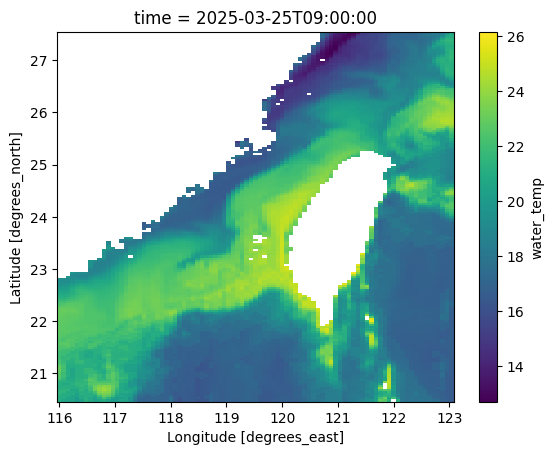

In [11]:
# Select a specific time step and print a horizontal figure of the data
time_step = 663
print(da.isel(time=time_step).mean(dim="depth").plot())

In [12]:
depth = ds[depth_name].values.astype(float)
n = depth.size

# 构造层界面深度 z_int（长度 n+1）
z_int = np.empty(n + 1, dtype=float)

# 顶界面：海面 0
z_int[0] = 0.0

# 中间界面：相邻中心深度的中点
z_int[1:n] = 0.5 * (depth[:-1] + depth[1:])

# 底界面：用最后两层间距外推一个半层厚
z_int[n] = depth[-1] + 0.5 * (depth[-1] - depth[-2])

dz = np.diff(z_int)  # 每层厚度，长度 n

dz_da = xr.DataArray(dz, coords={depth_name: ds[depth_name]}, dims=(depth_name,))
dz_da

<xarray.DataArray (depth: 39)> Size: 312B
array([   1. ,    2. ,    2. ,    2. ,    2. ,    2. ,    2.5,    4. ,
          5. ,    5. ,    5. ,    5. ,    5. ,    5. ,    7.5,   10. ,
         10. ,   10. ,   10. ,   17.5,   25. ,   37.5,   50. ,   50. ,
         50. ,   50. ,   75. ,  100. ,  100. ,  100. ,  100. ,  100. ,
        175. ,  250. ,  375. ,  500. ,  500. ,  750. , 1000. ])
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03

In [13]:
mask = da.notnull()

numerator = (da * dz_da).where(mask).sum(dim=depth_name)
denominator = (dz_da * mask).sum(dim=depth_name)

temp_depthmean = numerator / denominator
temp_depthmean.name = f"{var_name}_depthmean"
temp_depthmean

<xarray.DataArray 'water_temp_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
dask.array<truediv, shape=(2920, 177, 89), dtype=float64, chunksize=(24, 177, 89), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...

In [14]:
out = xr.Dataset(
    data_vars={temp_depthmean.name: temp_depthmean},
    coords={
        time_name: ds[time_name],
        lat_name:  ds[lat_name],
        lon_name:  ds[lon_name],
    },
    attrs=ds.attrs,  # 可选：继承原文件全局属性
)

out

<xarray.Dataset> Size: 368MB
Dimensions:               (lat: 177, lon: 89, time: 2920)
Coordinates:
  * lat                   (lat) float64 1kB 20.48 20.52 20.56 ... 27.48 27.52
  * lon                   (lon) float64 712B 116.0 116.1 116.2 ... 123.0 123.0
  * time                  (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... ...
Data variables:
    water_temp_depthmean  (time, lat, lon) float64 368MB dask.array<chunksize=(24, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.1.2, expt_03.1
    input_data_source:         FNMOC NAVGEM, Satellite SSH, SST, SMMI, in sit...
    reference:                 https://portal.fnmoc.navy.mil/
    created_on:                2026-01-01 02:24:20
    time_origin:               2025-12-31 12:00:00

In [15]:
encoding = {temp_depthmean.name: {"zlib": True, "complevel": 4, "_FillValue": None}}
out.to_netcdf(out_nc, encoding=encoding)

print("written:", out_nc)


written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\water_temp_depthmean.nc


In [16]:

import mikeio
from mikeio import Grid2D, Dataset
from mikeio.eum import ItemInfo, EUMType, EUMUnit


In [17]:
ds = xr.open_dataset(out_nc)
ds

<xarray.Dataset> Size: 368MB
Dimensions:               (lat: 177, lon: 89, time: 2920)
Coordinates:
  * lat                   (lat) float64 1kB 20.48 20.52 20.56 ... 27.48 27.52
  * lon                   (lon) float64 712B 116.0 116.1 116.2 ... 123.0 123.0
  * time                  (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... ...
Data variables:
    water_temp_depthmean  (time, lat, lon) float64 368MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.1.2, expt_03.1
    input_data_source:         FNMOC NAVGEM, Satellite SSH, SST, SMMI, in sit...
    reference:                 https://portal.fnmoc.navy.mil/
    created_on:                2026-01-01 02:24:20
    time_origin:               2025-12-31 12:00:00

In [18]:
var_name = list(ds.data_vars)[0]
da = ds[var_name]

print("Selected var:", var_name)
print(da)
print("dims:", da.dims)


Selected var: water_temp_depthmean
<xarray.DataArray 'water_temp_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
[45998760 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
dims: ('time', 'lat', 'lon')


In [19]:
# 统一维度名（你现在就是 lat/lon/time；这里保险起见做一次 assert）
assert "lat" in da.dims and "lon" in da.dims and "time" in da.dims, da.dims

# 若 lat/lon 不是递增，排序到递增
if np.any(np.diff(da["lat"].values) < 0):
    da = da.sortby("lat")
if np.any(np.diff(da["lon"].values) < 0):
    da = da.sortby("lon")

# 简单检查
print("lat increasing:", np.all(np.diff(da["lat"].values) > 0))
print("lon increasing:", np.all(np.diff(da["lon"].values) > 0))
print("lat range:", float(da.lat.min()), float(da.lat.max()))
print("lon range:", float(da.lon.min()), float(da.lon.max()))

lat increasing: True
lon increasing: True
lat range: 20.479999542236328 27.520000457763672
lon range: 116.0 123.0400390625


In [20]:

dlat = 0.04
dlon = 0.08

lat_min = float(da.lat.min())
lat_max = float(da.lat.max())
lon_min = float(da.lon.min())
lon_max = float(da.lon.max())


In [21]:
def regular_axis(vmin, vmax, dv, ndigits=6):
    n = int(np.floor((vmax - vmin) / dv + 0.5))  # 近似格点数-1
    axis = vmin + dv * np.arange(n + 1)
    return np.round(axis, ndigits)

new_lat = regular_axis(lat_min, lat_max, dlat)
new_lon = regular_axis(lon_min, lon_max, dlon)


print("new lat head/tail:", new_lat[:3], new_lat[-3:])
print("old lat head/tail:", lat_min, lat_max)
print("new lon head/tail:", new_lon[:3], new_lon[-3:])
print("old lon head/tail:", lon_min, lon_max)


new lat head/tail: [20.48 20.52 20.56] [27.44 27.48 27.52]
old lat head/tail: 20.479999542236328 27.520000457763672
new lon head/tail: [116.   116.08 116.16] [122.88 122.96 123.04]
old lon head/tail: 116.0 123.0400390625


In [22]:
ny0 = da.sizes["lat"]
nx0 = da.sizes["lon"]

print("original ny,nx:", ny0, nx0)
print("new      ny,nx:", len(new_lat), len(new_lon))

assert len(new_lat) == ny0, "new_lat 长度与原 lat 维度不一致：不插值则无法继续！"
assert len(new_lon) == nx0, "new_lon 长度与原 lon 维度不一致：不插值则无法继续！"

original ny,nx: 177 89
new      ny,nx: 177 89


In [23]:
# 只替换坐标（不改变 da.values）
da2 = da.assign_coords(lat=("lat", new_lat), lon=("lon", new_lon))

# 再确认一下
print(da2)
print("lat head/tail:", da2.lat.values[:3], da2.lat.values[-3:])
print("lon head/tail:", da2.lon.values[:3], da2.lon.values[-3:])

<xarray.DataArray 'water_temp_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
[45998760 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
lat head/tail: [20.48 20.52 20.56] [27.44 27.48 27.52]
lon head/tail: [116.   116.08 116.16] [122.88 122.96 123.04]


In [24]:
time = pd.DatetimeIndex(da2["time"].values)
print("time[0], time[-1], n=", time[0], time[-1], len(time))

# 可选：检查是否等间隔
if len(time) > 1:
    dt0 = (time[1] - time[0]).total_seconds()
    print("dt (s) guess:", dt0)

time[0], time[-1], n= 2025-01-01 12:00:00 2026-01-01 09:00:00 2920
dt (s) guess: 10800.0


In [25]:

g = Grid2D(x=new_lon, y=new_lat, projection="LONG/LAT")
g


<mikeio.Grid2D>
x: [116, 116.1, ..., 123] (nx=89, dx=0.08)
y: [20.48, 20.52, ..., 27.52] (ny=177, dy=0.04)
projection: LONG/LAT

In [26]:

item = ItemInfo(name=var_name, itemtype=EUMType.Temperature, unit=EUMUnit.degree_Celsius)
item


water_temp_depthmean <Temperature> (degree Celsius)

In [27]:

data = da2.values.astype(np.float32)  # 建议 float32 减小文件

print("data shape:", data.shape)  # 应该是 (time, lat, lon) = (nt, ny, nx)

out_dfs2 = out_nc.replace(".nc", f".dfs2")
print("Writing:", out_dfs2)

da_mi = mikeio.DataArray(data=data, time=time, item=item, geometry=g)
mikeio.Dataset([da_mi]).to_dfs(out_dfs2)



data shape: (2920, 177, 89)
Writing: C:\Project\2025_HT\Input\HYCOM_2025_monthly_T_qc\water_temp_depthmean.dfs2


# Salinity

In [2]:
month_file = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\HYCOM_2025_salinity_M12.nc"
out_file   = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\HYCOM_2025_salinity_M12_filled.nc"

with xr.open_dataset(month_file, decode_times=False) as ds:
    var = "salinity"  # 你这个月文件是 salinity

    da = ds[var]

    # 1) 找出“整个空间 + 全深度都缺测”的 time（占位一般是全 NaN/全 FillValue 解码后的 NaN）
    #    这一步不会改变数据，只生成一个 time 维度的 bool 向量
    missing_t = da.isnull().all(dim=("depth", "lat", "lon"))

    miss_idx = np.where(missing_t.values)[0]
    print("Missing time indices:", miss_idx)

    if miss_idx.size == 0:
        print("No missing slices found, nothing to do.")
        ds.to_netcdf(out_file)
    else:
        # 2) 复制一份，用于写回
        ds2 = ds.copy(deep=True)   # 子域不大时这样最简单
        da2 = ds2[var]

        for i in miss_idx:
            if i == 0 or i == da.sizes["time"] - 1:
                # 边界情况：没法做线性插值，就用相邻一侧复制
                j = 1 if i == 0 else i - 1
                fill = da.isel(time=j)
            else:
                prev = da.isel(time=i-1)   # (depth, lat, lon)
                next = da.isel(time=i+1)

                # 线性插值（等权 0.5），但要求 prev 和 next 都是有效值；
                # 任意一侧是 NaN -> 仍保持 NaN（陆地/缺测就不会被“填海”）
                fill = xr.where(np.isfinite(prev) & np.isfinite(next),
                                0.5*(prev + next),
                                np.nan)

            # 3) 写回该 time 切片（所有深度层同时写）
            da2[{ "time": i }] = fill

        # 4) 输出新文件（建议新文件名，避免覆盖原始月文件）
        ds2.to_netcdf(out_file)
ds2.close()
ds.close()
print("Saved:", out_file)


Missing time indices: [69]
Saved: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\HYCOM_2025_salinity_M12_filled.nc


In [3]:
data_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc"  # 放 nc 文件的目录，例如 r"D:\HYCOM\2025_temp"
pattern  = "HYCOM_2025_salinity_M*.nc"  # 文件名模式
out_nc   = "HYCOM_2025_salinity_ALL.nc" # 输出文件名

# （可选）只拼接某一个变量，减少内存和输出体积；不知道变量名就先 None
only_var = None   # 例如 "water_temp"；不知道就保持 None

In [4]:
files = glob.glob(os.path.join(data_dir, pattern))

def month_key(fname):
    # 从文件名里抓 "M01".."M12"
    m = re.search(r"_M(\d{2})\.nc$", os.path.basename(fname))
    return int(m.group(1)) if m else 999

files = sorted(files, key=month_key)

print("找到文件数:", len(files))
for f in files:
    print(" -", os.path.basename(f))

找到文件数: 13
 - HYCOM_2025_salinity_M01.nc
 - HYCOM_2025_salinity_M02.nc
 - HYCOM_2025_salinity_M03.nc
 - HYCOM_2025_salinity_M04.nc
 - HYCOM_2025_salinity_M05.nc
 - HYCOM_2025_salinity_M06.nc
 - HYCOM_2025_salinity_M07.nc
 - HYCOM_2025_salinity_M08.nc
 - HYCOM_2025_salinity_M09.nc
 - HYCOM_2025_salinity_M10.nc
 - HYCOM_2025_salinity_M11.nc
 - HYCOM_2025_salinity_M12.nc
 - HYCOM_2025_salinity_M12_bad.nc


In [5]:
for file in files:
    ds_check = xr.open_dataset(file, decode_times=False)
    ds_check = ds_check['salinity']
    x = ds_check.isel(depth=0)
    spstd = x.std(dim=('lat', 'lon'), skipna=True)
    bad = np.where(spstd.values < 1e-4)[0]
    print('bad time steps in', os.path.basename(file), ':', bad,'count=', len(bad))
    ds_check.close()




bad time steps in HYCOM_2025_salinity_M01.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M02.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M03.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M04.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M05.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M06.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M07.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M08.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M09.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M10.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M11.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M12.nc : [] count= 0
bad time steps in HYCOM_2025_salinity_M12_bad.nc : [] count= 0


C:\Users\casx\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [7]:
# 常见时间维度候选名（按优先级）
time_dim_candidates = ["time", "Time", "MT", "t", "datetime", "date"]

ds0 = xr.open_dataset(files[0])

print(ds0)
print("\n维度:", ds0.dims)
print("变量:", list(ds0.data_vars))

time_dim = None
for cand in time_dim_candidates:
    if cand in ds0.dims:
        time_dim = cand
        break

if time_dim is None:
    raise ValueError("没找到时间维度（time/MT/Time...）。请打开 ds0 看看实际维度名，然后手动指定。")

print("\n识别到时间维度:", time_dim)

<xarray.Dataset> Size: 609MB
Dimensions:   (time: 248, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth     (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat       (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.44 27.48 27.52
  * lon       (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time      (time) datetime64[ns] 2kB 2025-01-01T12:00:00 ... 2025-02-01T09...
Data variables:
    salinity  (time, depth, lat, lon) float32 609MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.

In [8]:
datasets = []

for f in files[:12]:
    print("读取:", os.path.basename(f))
    ds = xr.open_dataset(
        f,
        chunks={time_dim: 50}  # 适当调大/调小都行；或者删掉这一行做全内存
    )
    
    # （可选）只保留某个变量
    if only_var is not None:
        if only_var not in ds.data_vars:
            raise ValueError(f"{os.path.basename(f)} 里没有变量 {only_var}，请检查变量名。")
        ds = ds[[only_var]]
    
    datasets.append(ds)

# 拼接：沿 time_dim 维度连接
ds_all = xr.concat(datasets, dim=time_dim)

print(ds_all)

读取: HYCOM_2025_salinity_M01.nc
读取: HYCOM_2025_salinity_M02.nc
读取: HYCOM_2025_salinity_M03.nc
读取: HYCOM_2025_salinity_M04.nc
读取: HYCOM_2025_salinity_M05.nc
读取: HYCOM_2025_salinity_M06.nc
读取: HYCOM_2025_salinity_M07.nc
读取: HYCOM_2025_salinity_M08.nc
读取: HYCOM_2025_salinity_M09.nc
读取: HYCOM_2025_salinity_M10.nc
读取: HYCOM_2025_salinity_M11.nc
读取: HYCOM_2025_salinity_M12.nc
<xarray.Dataset> Size: 7GB
Dimensions:   (time: 2920, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth     (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat       (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.44 27.48 27.52
  * lon       (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time      (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T0...
Data variables:
    salinity  (time, depth, lat, lon) float32 7GB dask.array<chunksize=(50, 39, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approve

In [9]:
# 如果 time_dim 是坐标（通常是），可以排序
if time_dim in ds_all.coords:
    ds_all = ds_all.sortby(time_dim)

    # 去重（有些数据月末/下月初可能重叠）
    t = ds_all[time_dim].values
    _, idx = np.unique(t, return_index=True)
    if len(idx) != len(t):
        print(f"发现重复时间步: {len(t)-len(idx)} 个，已去重")
        idx = np.sort(idx)
        ds_all = ds_all.isel({time_dim: idx})

print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
if time_dim in ds_all.coords:
    print("时间范围:", str(ds_all[time_dim].values[0]), "->", str(ds_all[time_dim].values[-1]))

拼接后时间步数: 2920
时间范围: 2025-01-01T12:00:00.000000000 -> 2026-01-01T09:00:00.000000000


C:\Users\casx\AppData\Local\Temp\ipykernel_39432\3600626812.py:13: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
<frozen _collections_abc>:811: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [10]:
# 为所有数据变量设置压缩（zlib），并保留 dtype
encoding = {}
for v in ds_all.data_vars:
    encoding[v] = dict(zlib=True, complevel=4)

out_path = os.path.join(data_dir, out_nc)
print("写出:", out_path)

ds_all.to_netcdf(out_path, encoding=encoding)

print("完成 ✅")

写出: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\HYCOM_2025_salinity_ALL.nc
完成 ✅


C:\Users\casx\AppData\Roaming\Python\Python313\site-packages\dask\_task_spec.py:759: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


In [12]:
in_nc  = out_path
out_nc = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\salinity_depthmean.nc"

var_name = "salinity"      # 盐度变量名
depth_name = "depth"         # 深度维/坐标名
time_name  = "time"
lat_name   = "lat"
lon_name   = "lon"


In [13]:
# 不分块（最简单）
ds = xr.open_dataset(in_nc)

# 如果需要分块，改用这一行（需要 dask）：
ds = xr.open_dataset(in_nc, chunks={time_name: 24, lat_name: 177, lon_name: 89})

da = ds[var_name].transpose(time_name, depth_name, lat_name, lon_name)
da

c:\Users\casx\AppData\Local\Programs\Python\Python313\Lib\site-packages\xarray\backends\api.py:365: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 24. This could degrade performance. Instead, consider rechunking after loading.
  var_chunks = _get_chunk(var, chunks, chunkmanager)


<xarray.DataArray 'salinity' (time: 2920, depth: 39, lat: 177, lon: 89)> Size: 7GB
dask.array<open_dataset-salinity, shape=(2920, 39, 177, 89), dtype=float32, chunksize=(24, 8, 177, 89), chunktype=numpy.ndarray>
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
Attributes:
    long_name:      Salinity
    standard_name:  sea_water_salinity
    units:          psu
    NAVO_code:      16
    actual_range:   [ 0.9359989 48.326004 ]

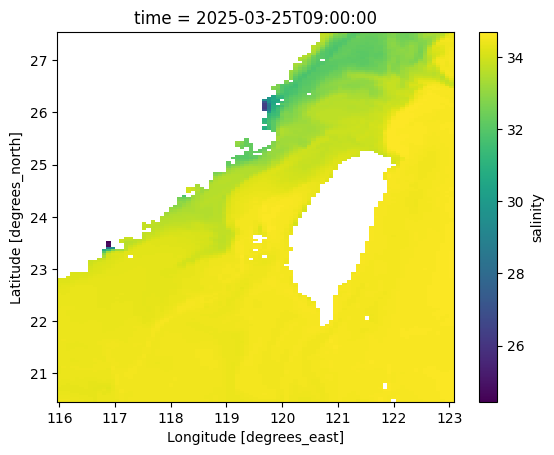

In [14]:
# Select a specific time step and print a horizontal figure of the data
time_step = 663
print(da.isel(time=time_step).mean(dim="depth").plot())

In [15]:
depth = ds[depth_name].values.astype(float)
n = depth.size

# 构造层界面深度 z_int（长度 n+1）
z_int = np.empty(n + 1, dtype=float)

# 顶界面：海面 0
z_int[0] = 0.0

# 中间界面：相邻中心深度的中点
z_int[1:n] = 0.5 * (depth[:-1] + depth[1:])

# 底界面：用最后两层间距外推一个半层厚
z_int[n] = depth[-1] + 0.5 * (depth[-1] - depth[-2])

dz = np.diff(z_int)  # 每层厚度，长度 n

dz_da = xr.DataArray(dz, coords={depth_name: ds[depth_name]}, dims=(depth_name,))
dz_da

<xarray.DataArray (depth: 39)> Size: 312B
array([   1. ,    2. ,    2. ,    2. ,    2. ,    2. ,    2.5,    4. ,
          5. ,    5. ,    5. ,    5. ,    5. ,    5. ,    7.5,   10. ,
         10. ,   10. ,   10. ,   17.5,   25. ,   37.5,   50. ,   50. ,
         50. ,   50. ,   75. ,  100. ,  100. ,  100. ,  100. ,  100. ,
        175. ,  250. ,  375. ,  500. ,  500. ,  750. , 1000. ])
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03

In [16]:
mask = da.notnull()

numerator = (da * dz_da).where(mask).sum(dim=depth_name)
denominator = (dz_da * mask).sum(dim=depth_name)

salinity_depthmean = numerator / denominator
salinity_depthmean.name = f"{var_name}_depthmean"
salinity_depthmean

<xarray.DataArray 'salinity_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
dask.array<truediv, shape=(2920, 177, 89), dtype=float64, chunksize=(24, 177, 89), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...

In [17]:
out = xr.Dataset(
    data_vars={salinity_depthmean.name: salinity_depthmean},
    coords={
        time_name: ds[time_name],
        lat_name:  ds[lat_name],
        lon_name:  ds[lon_name],
    },
    attrs=ds.attrs,  # 可选：继承原文件全局属性
)

out

<xarray.Dataset> Size: 368MB
Dimensions:             (lat: 177, lon: 89, time: 2920)
Coordinates:
  * lat                 (lat) float64 1kB 20.48 20.52 20.56 ... 27.48 27.52
  * lon                 (lon) float64 712B 116.0 116.1 116.2 ... 123.0 123.0
  * time                (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 20...
Data variables:
    salinity_depthmean  (time, lat, lon) float64 368MB dask.array<chunksize=(24, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.1.2, expt_03.1
    input_data_source:         FNMOC NAVGEM, Satellite SSH, SST, SMMI, in sit...
    reference:                 https://portal.fnmoc.navy.mil/
    created_on:                2026-01-01 02:14:01
    time_origin:               2025-12-31 12:00:00

In [20]:
encoding = {salinity_depthmean.name: {"zlib": True, "complevel": 4, "_FillValue": None}}
out.to_netcdf(out_nc, encoding=encoding)

print("written:", out_nc)


written: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\salinity_depthmean.nc


In [21]:

import mikeio
from mikeio import Grid2D, Dataset
from mikeio.eum import ItemInfo, EUMType, EUMUnit

In [22]:
ds = xr.open_dataset(out_nc)
ds

<xarray.Dataset> Size: 368MB
Dimensions:             (lat: 177, lon: 89, time: 2920)
Coordinates:
  * lat                 (lat) float64 1kB 20.48 20.52 20.56 ... 27.48 27.52
  * lon                 (lon) float64 712B 116.0 116.1 116.2 ... 123.0 123.0
  * time                (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 20...
Data variables:
    salinity_depthmean  (time, lat, lon) float64 368MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.1.2, expt_03.1
    input_data_source:         FNMOC NAVGEM, Satellite SSH, SST, SMMI, in sit...
    reference:                 https://portal.fnmoc.navy.mil/
    created_on:                2026-01-01 02:14:01
    time_origin:               2025-12-31 12:00:00

In [23]:
var_name = list(ds.data_vars)[0]
da = ds[var_name]

print("Selected var:", var_name)
print(da)
print("dims:", da.dims)


Selected var: salinity_depthmean
<xarray.DataArray 'salinity_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
[45998760 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
dims: ('time', 'lat', 'lon')


In [24]:
# 统一维度名（你现在就是 lat/lon/time；这里保险起见做一次 assert）
assert "lat" in da.dims and "lon" in da.dims and "time" in da.dims, da.dims

# 若 lat/lon 不是递增，排序到递增
if np.any(np.diff(da["lat"].values) < 0):
    da = da.sortby("lat")
if np.any(np.diff(da["lon"].values) < 0):
    da = da.sortby("lon")

# 简单检查
print("lat increasing:", np.all(np.diff(da["lat"].values) > 0))
print("lon increasing:", np.all(np.diff(da["lon"].values) > 0))
print("lat range:", float(da.lat.min()), float(da.lat.max()))
print("lon range:", float(da.lon.min()), float(da.lon.max()))

lat increasing: True
lon increasing: True
lat range: 20.479999542236328 27.520000457763672
lon range: 116.0 123.0400390625


In [25]:

dlat = 0.04
dlon = 0.08

lat_min = float(da.lat.min())
lat_max = float(da.lat.max())
lon_min = float(da.lon.min())
lon_max = float(da.lon.max())

In [26]:
def regular_axis(vmin, vmax, dv, ndigits=6):
    n = int(np.floor((vmax - vmin) / dv + 0.5))  # 近似格点数-1
    axis = vmin + dv * np.arange(n + 1)
    return np.round(axis, ndigits)

new_lat = regular_axis(lat_min, lat_max, dlat)
new_lon = regular_axis(lon_min, lon_max, dlon)


print("new lat head/tail:", new_lat[:3], new_lat[-3:])
print("old lat head/tail:", lat_min, lat_max)
print("new lon head/tail:", new_lon[:3], new_lon[-3:])
print("old lon head/tail:", lon_min, lon_max)


new lat head/tail: [20.48 20.52 20.56] [27.44 27.48 27.52]
old lat head/tail: 20.479999542236328 27.520000457763672
new lon head/tail: [116.   116.08 116.16] [122.88 122.96 123.04]
old lon head/tail: 116.0 123.0400390625


In [27]:
ny0 = da.sizes["lat"]
nx0 = da.sizes["lon"]

print("original ny,nx:", ny0, nx0)
print("new      ny,nx:", len(new_lat), len(new_lon))

assert len(new_lat) == ny0, "new_lat 长度与原 lat 维度不一致：不插值则无法继续！"
assert len(new_lon) == nx0, "new_lon 长度与原 lon 维度不一致：不插值则无法继续！"

original ny,nx: 177 89
new      ny,nx: 177 89


In [28]:
# 只替换坐标（不改变 da.values）
da2 = da.assign_coords(lat=("lat", new_lat), lon=("lon", new_lon))

# 再确认一下
print(da2)
print("lat head/tail:", da2.lat.values[:3], da2.lat.values[-3:])
print("lon head/tail:", da2.lon.values[:3], da2.lon.values[-3:])

<xarray.DataArray 'salinity_depthmean' (time: 2920, lat: 177, lon: 89)> Size: 368MB
[45998760 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
lat head/tail: [20.48 20.52 20.56] [27.44 27.48 27.52]
lon head/tail: [116.   116.08 116.16] [122.88 122.96 123.04]


In [29]:
time = pd.DatetimeIndex(da2["time"].values)
print("time[0], time[-1], n=", time[0], time[-1], len(time))

# 可选：检查是否等间隔
if len(time) > 1:
    dt0 = (time[1] - time[0]).total_seconds()
    print("dt (s) guess:", dt0)

time[0], time[-1], n= 2025-01-01 12:00:00 2026-01-01 09:00:00 2920
dt (s) guess: 10800.0


In [30]:

g = Grid2D(x=new_lon, y=new_lat, projection="LONG/LAT")
item = ItemInfo(name=var_name, itemtype=EUMType.Salinity, unit=EUMUnit.PSU)


In [31]:

data = da2.values.astype(np.float32)  # 建议 float32 减小文件

print("data shape:", data.shape)  # 应该是 (time, lat, lon) = (nt, ny, nx)

out_dfs2 = out_nc.replace(".nc", f".dfs2")
print("Writing:", out_dfs2)

da_mi = mikeio.DataArray(data=data, time=time, item=item, geometry=g)
mikeio.Dataset([da_mi]).to_dfs(out_dfs2)

data shape: (2920, 177, 89)
Writing: C:\Project\2025_HT\Input\HYCOM_2025_monthly_S_qc\salinity_depthmean.dfs2


# U

In [2]:
data_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc"  # 放 nc 文件的目录，例如 r"D:\HYCOM\2025_temp"
pattern  = "HYCOM_2025_U_M*.nc"  # 文件名模式
out_nc   = "HYCOM_2025_U_ALL.nc" # 输出文件名

# （可选）只拼接某一个变量，减少内存和输出体积；不知道变量名就先 None
only_var = None   # 例如 "water_temp"；不知道就保持 None

In [3]:
files = glob.glob(os.path.join(data_dir, pattern))

def month_key(fname):
    # 从文件名里抓 "M01".."M12"
    m = re.search(r"_M(\d{2})\.nc$", os.path.basename(fname))
    return int(m.group(1)) if m else 999

files = sorted(files, key=month_key)

print("找到文件数:", len(files))
for f in files:
    print(" -", os.path.basename(f))

找到文件数: 12
 - HYCOM_2025_U_M01.nc
 - HYCOM_2025_U_M02.nc
 - HYCOM_2025_U_M03.nc
 - HYCOM_2025_U_M04.nc
 - HYCOM_2025_U_M05.nc
 - HYCOM_2025_U_M06.nc
 - HYCOM_2025_U_M07.nc
 - HYCOM_2025_U_M08.nc
 - HYCOM_2025_U_M09.nc
 - HYCOM_2025_U_M10.nc
 - HYCOM_2025_U_M11.nc
 - HYCOM_2025_U_M12.nc


In [5]:
for file in files:
    ds_check = xr.open_dataset(file, decode_times=False)
    ds_check = ds_check['water_u']
    x = ds_check.isel(depth=0)
    spstd = x.std(dim=('lat', 'lon'), skipna=True)
    bad = np.where(spstd.values < 1e-4)[0]
    print('bad time steps in', os.path.basename(file), ':', bad,'count=', len(bad))
    ds_check.close()

bad time steps in HYCOM_2025_U_M01.nc : [] count= 0
bad time steps in HYCOM_2025_U_M02.nc : [] count= 0
bad time steps in HYCOM_2025_U_M03.nc : [] count= 0
bad time steps in HYCOM_2025_U_M04.nc : [] count= 0
bad time steps in HYCOM_2025_U_M05.nc : [] count= 0
bad time steps in HYCOM_2025_U_M06.nc : [] count= 0
bad time steps in HYCOM_2025_U_M07.nc : [] count= 0
bad time steps in HYCOM_2025_U_M08.nc : [] count= 0
bad time steps in HYCOM_2025_U_M09.nc : [] count= 0
bad time steps in HYCOM_2025_U_M10.nc : [] count= 0
bad time steps in HYCOM_2025_U_M11.nc : [] count= 0
bad time steps in HYCOM_2025_U_M12.nc : [] count= 0


In [6]:
# 常见时间维度候选名（按优先级）
time_dim_candidates = ["time", "Time", "MT", "t", "datetime", "date"]

ds0 = xr.open_dataset(files[0])

print(ds0)
print("\n维度:", ds0.dims)
print("变量:", list(ds0.data_vars))

time_dim = None
for cand in time_dim_candidates:
    if cand in ds0.dims:
        time_dim = cand
        break

if time_dim is None:
    raise ValueError("没找到时间维度（time/MT/Time...）。请打开 ds0 看看实际维度名，然后手动指定。")

print("\n识别到时间维度:", time_dim)

<xarray.Dataset> Size: 609MB
Dimensions:  (time: 248, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 2kB 2025-01-01T12:00:00 ... 2025-02-01T09:...
Data variables:
    water_u  (time, depth, lat, lon) float32 609MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.

In [7]:
datasets = []

for f in files[:12]:
    print("读取:", os.path.basename(f))
    ds = xr.open_dataset(
        f,
        chunks={time_dim: 50}  # 适当调大/调小都行；或者删掉这一行做全内存
    )
    
    # （可选）只保留某个变量
    if only_var is not None:
        if only_var not in ds.data_vars:
            raise ValueError(f"{os.path.basename(f)} 里没有变量 {only_var}，请检查变量名。")
        ds = ds[[only_var]]
    
    datasets.append(ds)

# 拼接：沿 time_dim 维度连接
ds_all = xr.concat(datasets, dim=time_dim)

print(ds_all)

读取: HYCOM_2025_U_M01.nc
读取: HYCOM_2025_U_M02.nc
读取: HYCOM_2025_U_M03.nc
读取: HYCOM_2025_U_M04.nc
读取: HYCOM_2025_U_M05.nc
读取: HYCOM_2025_U_M06.nc
读取: HYCOM_2025_U_M07.nc
读取: HYCOM_2025_U_M08.nc
读取: HYCOM_2025_U_M09.nc
读取: HYCOM_2025_U_M10.nc
读取: HYCOM_2025_U_M11.nc
读取: HYCOM_2025_U_M12.nc
<xarray.Dataset> Size: 7GB
Dimensions:  (time: 2920, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
Data variables:
    water_u  (time, depth, lat, lon) float32 7GB dask.array<chunksize=(50, 39, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applic

In [8]:
# 如果 time_dim 是坐标（通常是），可以排序
if time_dim in ds_all.coords:
    ds_all = ds_all.sortby(time_dim)

    # 去重（有些数据月末/下月初可能重叠）
    t = ds_all[time_dim].values
    _, idx = np.unique(t, return_index=True)
    if len(idx) != len(t):
        print(f"发现重复时间步: {len(t)-len(idx)} 个，已去重")
        idx = np.sort(idx)
        ds_all = ds_all.isel({time_dim: idx})

print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
if time_dim in ds_all.coords:
    print("时间范围:", str(ds_all[time_dim].values[0]), "->", str(ds_all[time_dim].values[-1]))

拼接后时间步数: 2920
时间范围: 2025-01-01T12:00:00.000000000 -> 2026-01-01T09:00:00.000000000


C:\Users\casx\AppData\Local\Temp\ipykernel_2920\3600626812.py:13: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
<frozen _collections_abc>:811: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [9]:
# 为所有数据变量设置压缩（zlib），并保留 dtype
encoding = {}
for v in ds_all.data_vars:
    encoding[v] = dict(zlib=True, complevel=4)

out_path = os.path.join(data_dir, out_nc)
print("写出:", out_path)

ds_all.to_netcdf(out_path, encoding=encoding)

print("完成 ✅")

写出: C:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL.nc
完成 ✅


# V

In [10]:
data_dir = r"C:\Project\2025_HT\Input\HYCOM_2025_monthly_V_qc"  # 放 nc 文件的目录，例如 r"D:\HYCOM\2025_temp"
pattern  = "HYCOM_2025_V_M*.nc"  # 文件名模式
out_nc   = "HYCOM_2025_V_ALL.nc" # 输出文件名

# （可选）只拼接某一个变量，减少内存和输出体积；不知道变量名就先 None
only_var = None   # 例如 "water_temp"；不知道就保持 None

In [11]:
files = glob.glob(os.path.join(data_dir, pattern))

def month_key(fname):
    # 从文件名里抓 "M01".."M12"
    m = re.search(r"_M(\d{2})\.nc$", os.path.basename(fname))
    return int(m.group(1)) if m else 999

files = sorted(files, key=month_key)

print("找到文件数:", len(files))
for f in files:
    print(" -", os.path.basename(f))

找到文件数: 12
 - HYCOM_2025_V_M01.nc
 - HYCOM_2025_V_M02.nc
 - HYCOM_2025_V_M03.nc
 - HYCOM_2025_V_M04.nc
 - HYCOM_2025_V_M05.nc
 - HYCOM_2025_V_M06.nc
 - HYCOM_2025_V_M07.nc
 - HYCOM_2025_V_M08.nc
 - HYCOM_2025_V_M09.nc
 - HYCOM_2025_V_M10.nc
 - HYCOM_2025_V_M11.nc
 - HYCOM_2025_V_M12.nc


In [13]:
for file in files:
    ds_check = xr.open_dataset(file, decode_times=False)
    ds_check = ds_check['water_v']
    x = ds_check.isel(depth=0)
    spstd = x.std(dim=('lat', 'lon'), skipna=True)
    bad = np.where(spstd.values < 1e-4)[0]
    print('bad time steps in', os.path.basename(file), ':', bad,'count=', len(bad))
    ds_check.close()

bad time steps in HYCOM_2025_V_M01.nc : [] count= 0
bad time steps in HYCOM_2025_V_M02.nc : [] count= 0
bad time steps in HYCOM_2025_V_M03.nc : [] count= 0
bad time steps in HYCOM_2025_V_M04.nc : [] count= 0
bad time steps in HYCOM_2025_V_M05.nc : [] count= 0
bad time steps in HYCOM_2025_V_M06.nc : [] count= 0
bad time steps in HYCOM_2025_V_M07.nc : [] count= 0
bad time steps in HYCOM_2025_V_M08.nc : [] count= 0
bad time steps in HYCOM_2025_V_M09.nc : [] count= 0
bad time steps in HYCOM_2025_V_M10.nc : [] count= 0
bad time steps in HYCOM_2025_V_M11.nc : [] count= 0
bad time steps in HYCOM_2025_V_M12.nc : [] count= 0


In [14]:
# 常见时间维度候选名（按优先级）
time_dim_candidates = ["time", "Time", "MT", "t", "datetime", "date"]

ds0 = xr.open_dataset(files[0])

print(ds0)
print("\n维度:", ds0.dims)
print("变量:", list(ds0.data_vars))

time_dim = None
for cand in time_dim_candidates:
    if cand in ds0.dims:
        time_dim = cand
        break

if time_dim is None:
    raise ValueError("没找到时间维度（time/MT/Time...）。请打开 ds0 看看实际维度名，然后手动指定。")

print("\n识别到时间维度:", time_dim)

<xarray.Dataset> Size: 609MB
Dimensions:  (time: 248, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 2kB 2025-01-01T12:00:00 ... 2025-02-01T09:...
Data variables:
    water_v  (time, depth, lat, lon) float32 609MB ...
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applicable
    classification_authority:  not applicable
    institution:               Fleet Numerical Meteorology and Oceanography C...
    source:                    HYCOM archive file, GLBz0.04
    ...                        ...
    operational_status:        pre-operational
    generating_model:          ESPC-D V02: HYCOM 2.2.99, CICE 5.

In [15]:
datasets = []

for f in files[:12]:
    print("读取:", os.path.basename(f))
    ds = xr.open_dataset(
        f,
        chunks={time_dim: 50}  # 适当调大/调小都行；或者删掉这一行做全内存
    )
    
    # （可选）只保留某个变量
    if only_var is not None:
        if only_var not in ds.data_vars:
            raise ValueError(f"{os.path.basename(f)} 里没有变量 {only_var}，请检查变量名。")
        ds = ds[[only_var]]
    
    datasets.append(ds)

# 拼接：沿 time_dim 维度连接
ds_all = xr.concat(datasets, dim=time_dim)

print(ds_all)

读取: HYCOM_2025_V_M01.nc
读取: HYCOM_2025_V_M02.nc
读取: HYCOM_2025_V_M03.nc
读取: HYCOM_2025_V_M04.nc
读取: HYCOM_2025_V_M05.nc
读取: HYCOM_2025_V_M06.nc
读取: HYCOM_2025_V_M07.nc
读取: HYCOM_2025_V_M08.nc
读取: HYCOM_2025_V_M09.nc
读取: HYCOM_2025_V_M10.nc
读取: HYCOM_2025_V_M11.nc
读取: HYCOM_2025_V_M12.nc
<xarray.Dataset> Size: 7GB
Dimensions:  (time: 2920, depth: 39, lat: 177, lon: 89)
Coordinates:
  * depth    (depth) float64 312B 0.0 2.0 4.0 6.0 ... 2e+03 2.5e+03 3e+03 4e+03
  * lat      (lat) float64 1kB 20.48 20.52 20.56 20.6 ... 27.4 27.44 27.48 27.52
  * lon      (lon) float64 712B 116.0 116.1 116.2 116.2 ... 122.9 123.0 123.0
  * time     (time) datetime64[ns] 23kB 2025-01-01T12:00:00 ... 2026-01-01T09...
Data variables:
    water_v  (time, depth, lat, lon) float32 7GB dask.array<chunksize=(50, 39, 177, 89), meta=np.ndarray>
Attributes: (12/17)
    classification_level:      
    distribution_statement:    Approved for public release; distribution unli...
    downgrade_date:            not applic

In [16]:
# 如果 time_dim 是坐标（通常是），可以排序
if time_dim in ds_all.coords:
    ds_all = ds_all.sortby(time_dim)

    # 去重（有些数据月末/下月初可能重叠）
    t = ds_all[time_dim].values
    _, idx = np.unique(t, return_index=True)
    if len(idx) != len(t):
        print(f"发现重复时间步: {len(t)-len(idx)} 个，已去重")
        idx = np.sort(idx)
        ds_all = ds_all.isel({time_dim: idx})

print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
if time_dim in ds_all.coords:
    print("时间范围:", str(ds_all[time_dim].values[0]), "->", str(ds_all[time_dim].values[-1]))

拼接后时间步数: 2920
时间范围: 2025-01-01T12:00:00.000000000 -> 2026-01-01T09:00:00.000000000


C:\Users\casx\AppData\Local\Temp\ipykernel_2920\3600626812.py:13: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("拼接后时间步数:", ds_all.dims.get(time_dim, "N/A"))
<frozen _collections_abc>:811: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


In [ ]:
# 为所有数据变量设置压缩（zlib），并保留 dtype
encoding = {}
for v in ds_all.data_vars:
    encoding[v] = dict(zlib=True, complevel=4)

out_path = os.path.join(data_dir, out_nc)
print("写出:", out_path)

ds_all.to_netcdf(out_path, encoding=encoding)

print("完成 ✅")

写出: C:\Project\2025_HT\Input\HYCOM_2025_monthly_V_qc\HYCOM_2025_V_ALL.nc
完成 ✅


: 